In [1]:
#Khai báo các thư viện/hàm cần dùng
import sys
sys.path.append("..") #add thư mục gốc vào path để import các module con để chạy đc src bên dưới nè

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import classification_report

from src.models.complex_cnn import build_model
from src.data.preprocess import preprocess_image

ModuleNotFoundError: No module named 'src'

In [2]:
#Đọc và chuẩn bị dữ liệu
train_df = pd.read_csv("../data/train_split.csv")
val_df = pd.read_csv("../data/validation_split.csv")
test_df = pd.read_csv("../data/test_split.csv")

train_paths = ("../data/" + train_df["file_name"]).to_numpy()
val_paths = ("../data/" + val_df["file_name"]).to_numpy()
test_paths = ("../data/" + test_df["file_name"]).to_numpy()

y_train = train_df["label"].to_numpy(dtype="float32")
y_val = val_df["label"].to_numpy(dtype="float32")
y_test = test_df["label"].to_numpy(dtype="float32")


def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = image / 255.0
    return image, label


batch_size = 16

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, y_train))
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.map(load_image, num_parallel_calls=2)
train_ds = train_ds.batch(batch_size).prefetch(1)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, y_val))
val_ds = val_ds.map(load_image, num_parallel_calls=2)
val_ds = val_ds.batch(batch_size).prefetch(1)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, y_test))
test_ds = test_ds.map(load_image, num_parallel_calls=2)
test_ds = test_ds.batch(batch_size).prefetch(1)

In [3]:
#Xây dựng model
model = build_model()
model.summary()

Model: "Complex_CNN_4_Blocks"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 224, 224,  │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     18,432 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │     36,864 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │      2,048 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_4[0][0]  

 Total params: 1,262,305 (4.82 MB)

 Trainable params: 1,259,425 (4.80 MB)

 Non-trainable params: 2,880 (11.25 KB)

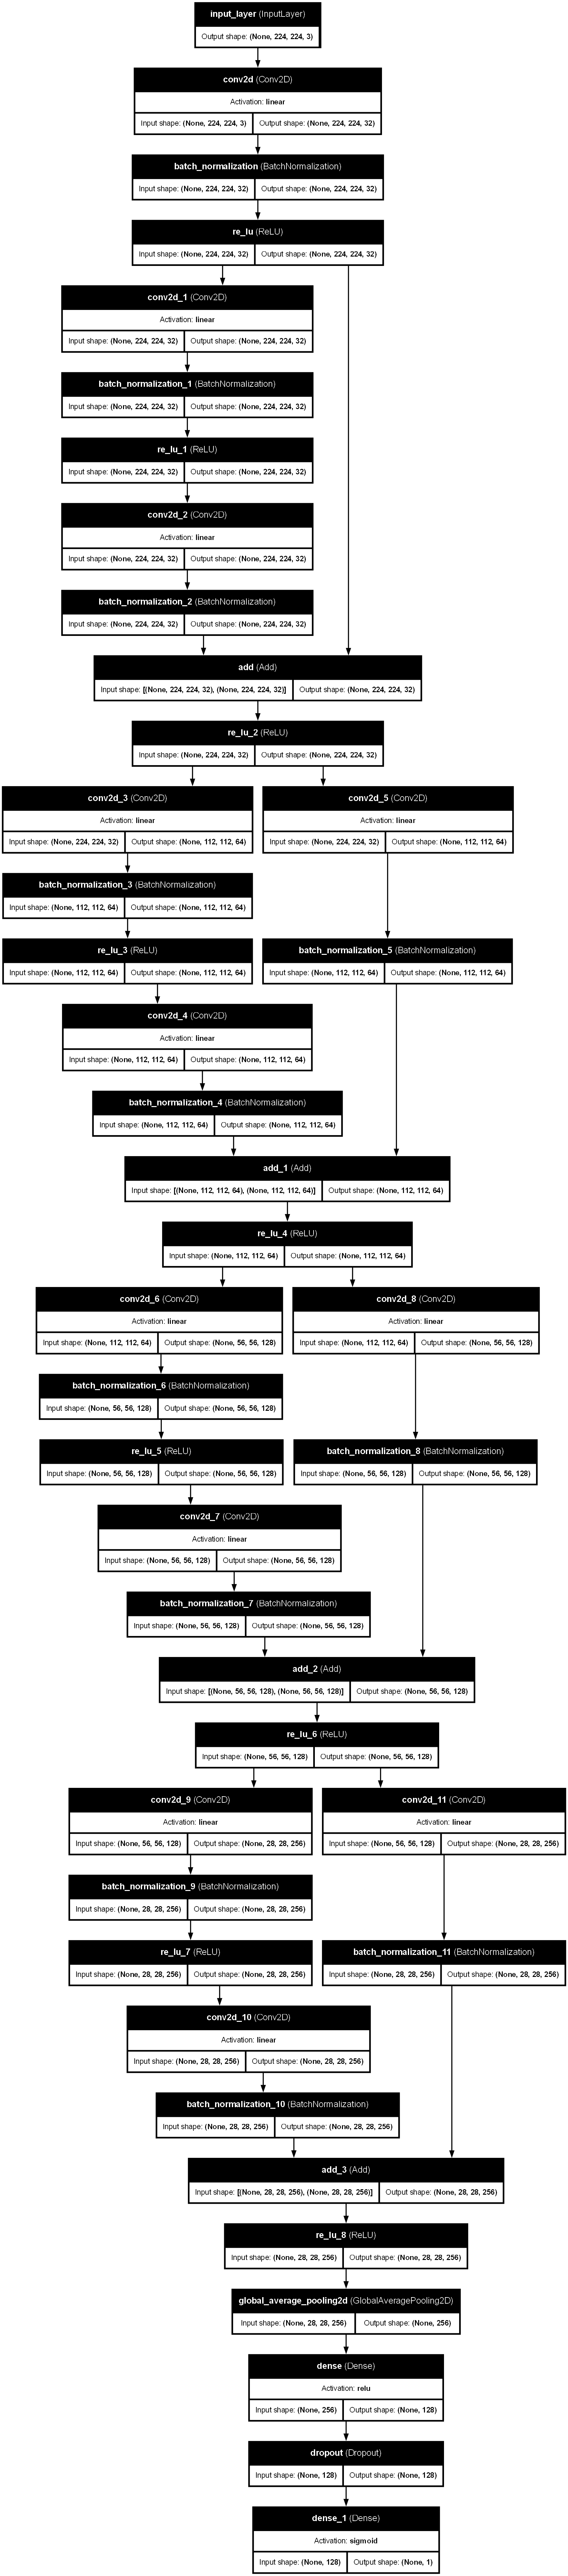

In [4]:
#Vẽ kiến trúc Complex CNN
tf.keras.utils.plot_model(model, to_file="../results/figures/complex_cnn_architecture.png", show_shapes=True, show_layer_names=True, show_layer_activations=True, dpi=120)

In [ ]:
#Training model
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

In [6]:
#Lưu model
model.save("../src/models/complex_cnn.keras")

In [8]:
# Đánh giá model trên tập test
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)

In [ ]:
# Dự đoán nhãn trên tập test
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

In [ ]:
# Tính các chỉ số đánh giá
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

In [ ]:
# Báo cáo phân loại
print(classification_report(y_test, y_pred, zero_division=0))